# Nivel beginner — Trayectorias UAV y B-splines desde cero

**Perfil:** estudiantes que todavía no programan y no han estudiado cálculo.

En este cuaderno aprenderás a:

1. ejecutar código en Google Colab;
2. reconocer una tabla de datos;
3. ver la trayectoria de un UAV;
4. entender qué significa “centrar” una coordenada;
5. usar una curva suave para describir el movimiento;
6. interpretar crecimiento, decrecimiento, máximos y mínimos de forma visual.

> No necesitas escribir código desde cero. Ejecuta las celdas en orden con el botón ▶.

## 1. Tres ideas antes de empezar

- Una **fila** es una medición del UAV.
- Las columnas `tx`, `ty` y `tz` indican su posición en tres direcciones.
- Una **B-spline** es una curva suave que sigue la tendencia de los datos sin unirlos con líneas quebradas.

En este nivel estudiaremos primero una sola coordenada: **x**.

## 2. Preparar Colab

Esta celda instala las bibliotecas. No hace falta comprenderla todavía.

In [ ]:
!pip -q install "numpy>=1.24" "pandas>=2.0" "scipy>=1.8" "matplotlib>=3.7" "datasets>=2.18" "pyarrow>=14"

## 3. Importar herramientas y elegir parámetros

Una variable es una “caja con nombre”. Puedes cambiar solo los valores marcados como editables.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from scipy.interpolate import UnivariateSpline
from IPython.display import display

DATASET_ID = "riotu-lab/Synthetic-UAV-Flight-Trajectories"

# Parámetros editables
NUMERO_FILAS = 80_000
TRAYECTORIA = 0
EJE = "x"              # prueba también "y" o "z"
SUAVIZADO = 0.02       # 0 sigue todos los puntos; valores mayores suavizan más

print("Herramientas preparadas.")

Herramientas preparadas.


## 4. Descargar una parte del dataset

El dataset completo es grande. Para aprender usamos una muestra.

In [ ]:
columnas = ["timestamp", "tx", "ty", "tz"]

flujo = load_dataset(
    DATASET_ID,
    split="train",
    streaming=True,
)

filas = (
    {columna: fila[columna] for columna in columnas}
    for fila in flujo.take(NUMERO_FILAS)
)

df = pd.DataFrame(filas)

print(f"Filas descargadas: {len(df):,}")
display(df.head())

README.md:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/5093 [00:00<?, ?it/s]

Filas descargadas: 80,000


,timestamp,tx,ty,tz
0,1.700250e+09,-20.110498,2.792424,17.071516
1,1.700250e+09,-20.027747,2.781007,17.104970
2,1.700250e+09,-19.958962,2.779229,17.148497
3,1.700250e+09,-19.898282,2.804703,17.221119
4,1.700250e+09,-19.857856,2.868688,17.274563


## 5. Limpiar y separar vuelos

Esta es una **función auxiliar** ya preparada. Su tarea es:

- quitar datos incompletos;
- detectar cuándo termina un vuelo y empieza otro;
- asignar un número a cada trayectoria.

En este nivel basta con ejecutarla.

In [ ]:
def preparar_datos(tabla):
    tabla = tabla.copy()

    for columna in ["timestamp", "tx", "ty", "tz"]:
        tabla[columna] = pd.to_numeric(tabla[columna], errors="coerce")

    tabla = (
        tabla.replace([np.inf, -np.inf], np.nan)
             .dropna()
             .reset_index(drop=True)
    )

    tiempos = tabla["timestamp"].to_numpy(dtype=float)
    saltos = np.diff(tiempos)
    saltos_positivos = saltos[saltos > 0]

    if len(saltos_positivos) == 0:
        raise ValueError("No se pudieron ordenar los tiempos.")

    paso_normal = np.median(saltos_positivos)
    nuevo_vuelo = (saltos <= 0) | (saltos > 5 * paso_normal)

    tabla["trajectory_id"] = np.cumsum(
        np.r_[True, nuevo_vuelo]
    ) - 1

    return tabla


df = preparar_datos(df)

tamanos = df.groupby("trajectory_id").size().sort_values(ascending=False)
trayectorias_validas = tamanos[tamanos >= 8].index.to_list()

print(f"Trayectorias detectadas: {df['trajectory_id'].nunique()}")
print("Primeros tamaños:")
display(tamanos.head(10).to_frame("número de puntos"))

Trayectorias detectadas: 456
Primeros tamaños:


,número de puntos
trajectory_id,
387,252
386,251
20,251
411,249
400,249
265,249
218,249
85,247
314,247


## 6. Elegir una trayectoria

`TRAYECTORIA = 0` significa “usar la primera trayectoria válida”.  
Puedes cambiarlo por 1, 2, 3... y volver a ejecutar desde esta celda.

In [ ]:
if TRAYECTORIA < 0 or TRAYECTORIA >= len(trayectorias_validas):
    raise ValueError(
        f"Elige TRAYECTORIA entre 0 y {len(trayectorias_validas) - 1}."
    )

trajectory_id = trayectorias_validas[TRAYECTORIA]

trayectoria = (
    df.loc[
        df["trajectory_id"] == trajectory_id,
        ["timestamp", "tx", "ty", "tz"],
    ]
    .groupby("timestamp", as_index=False)
    .mean()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

trayectoria["t"] = (
    trayectoria["timestamp"] - trayectoria["timestamp"].iloc[0]
)

print(f"Trayectoria usada: {trajectory_id}")
print(f"Puntos: {len(trayectoria)}")
print(f"Duración: {trayectoria['t'].iloc[-1]:.2f} segundos")
display(trayectoria.head())

Trayectoria usada: 387
Puntos: 252
Duración: 25.10 segundos


,timestamp,tx,ty,tz,t
0,1.700275e+09,22.726160,-33.313290,14.148840,0.0
1,1.700275e+09,22.819872,-33.720849,14.154008,0.1
2,1.700275e+09,22.885149,-34.014497,14.163690,0.2
3,1.700275e+09,22.952103,-34.240799,14.167485,0.3
4,1.700275e+09,23.014135,-34.359177,14.168497,0.4


## 7. Ver el vuelo en 3D

Cada punto representa una posición medida. La línea muestra el orden del movimiento.

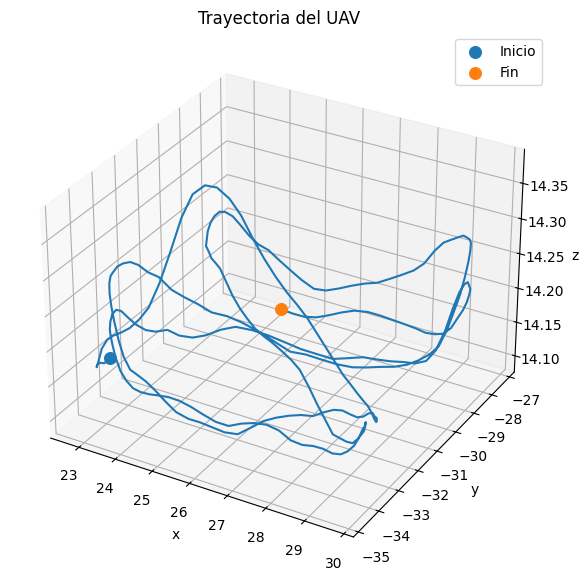

In [ ]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    trayectoria["tx"],
    trayectoria["ty"],
    trayectoria["tz"],
)
ax.scatter(
    trayectoria["tx"].iloc[0],
    trayectoria["ty"].iloc[0],
    trayectoria["tz"].iloc[0],
    s=70,
    label="Inicio",
)
ax.scatter(
    trayectoria["tx"].iloc[-1],
    trayectoria["ty"].iloc[-1],
    trayectoria["tz"].iloc[-1],
    s=70,
    label="Fin",
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Trayectoria del UAV")
ax.legend()
plt.show()

## 8. Centrar las coordenadas

Primero calculamos el promedio. Después restamos ese promedio a cada valor.

\[
\text{valor centrado}=\text{valor original}-\text{promedio}
\]

Así:

- un valor positivo está por encima del promedio;
- un valor negativo está por debajo;
- cero significa “igual al promedio”.

,t,fx,fy,fz
0,0.0,-3.517846,-2.090395,-0.034128
1,0.1,-3.424134,-2.497955,-0.028960
2,0.2,-3.358858,-2.791603,-0.019278
3,0.3,-3.291904,-3.017904,-0.015482
4,0.4,-3.229871,-3.136283,-0.014471


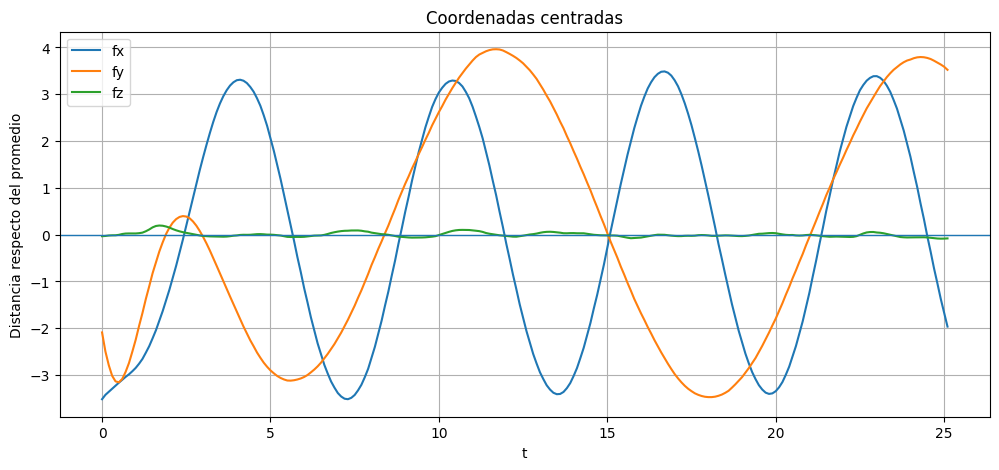

In [ ]:
for letra, columna in {"x": "tx", "y": "ty", "z": "tz"}.items():
    promedio = trayectoria[columna].mean()
    trayectoria[f"f{letra}"] = trayectoria[columna] - promedio

display(trayectoria[["t", "fx", "fy", "fz"]].head())

trayectoria.plot(
    x="t",
    y=["fx", "fy", "fz"],
    figsize=(12, 5),
    grid=True,
    title="Coordenadas centradas",
)
plt.axhline(0, linewidth=1)
plt.ylabel("Distancia respecto del promedio")
plt.show()

## 9. Construir una curva suave

La spline no cambia los datos originales. Crea una curva matemática para ver mejor la tendencia.

Usaremos el eje elegido en `EJE`.

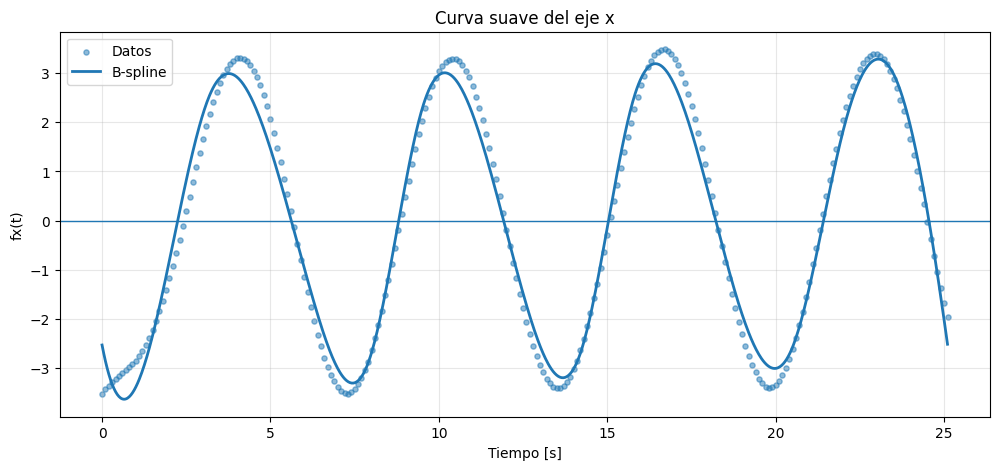

In [ ]:
if EJE not in ["x", "y", "z"]:
    raise ValueError('EJE debe ser "x", "y" o "z".')

t = trayectoria["t"].to_numpy(dtype=float)
valores = trayectoria[f"f{EJE}"].to_numpy(dtype=float)

cantidad_suavizado = len(t) * SUAVIZADO * np.var(valores)
spline = UnivariateSpline(t, valores, k=3, s=cantidad_suavizado)

tiempo_suave = np.linspace(t[0], t[-1], 1000)
curva_suave = spline(tiempo_suave)

plt.figure(figsize=(12, 5))
plt.scatter(t, valores, s=14, alpha=0.5, label="Datos")
plt.plot(tiempo_suave, curva_suave, linewidth=2, label="B-spline")
plt.axhline(0, linewidth=1)
plt.xlabel("Tiempo [s]")
plt.ylabel(f"f{EJE}(t)")
plt.title(f"Curva suave del eje {EJE}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 10. Leer el movimiento con dos curvas nuevas

La primera derivada responde: **¿la curva sube o baja?**

- \(f'(t)>0\): sube;
- \(f'(t)<0\): baja.

La segunda derivada ayuda a describir cómo cambia la inclinación de la curva. En este nivel la observaremos, sin hacer cálculos manuales.

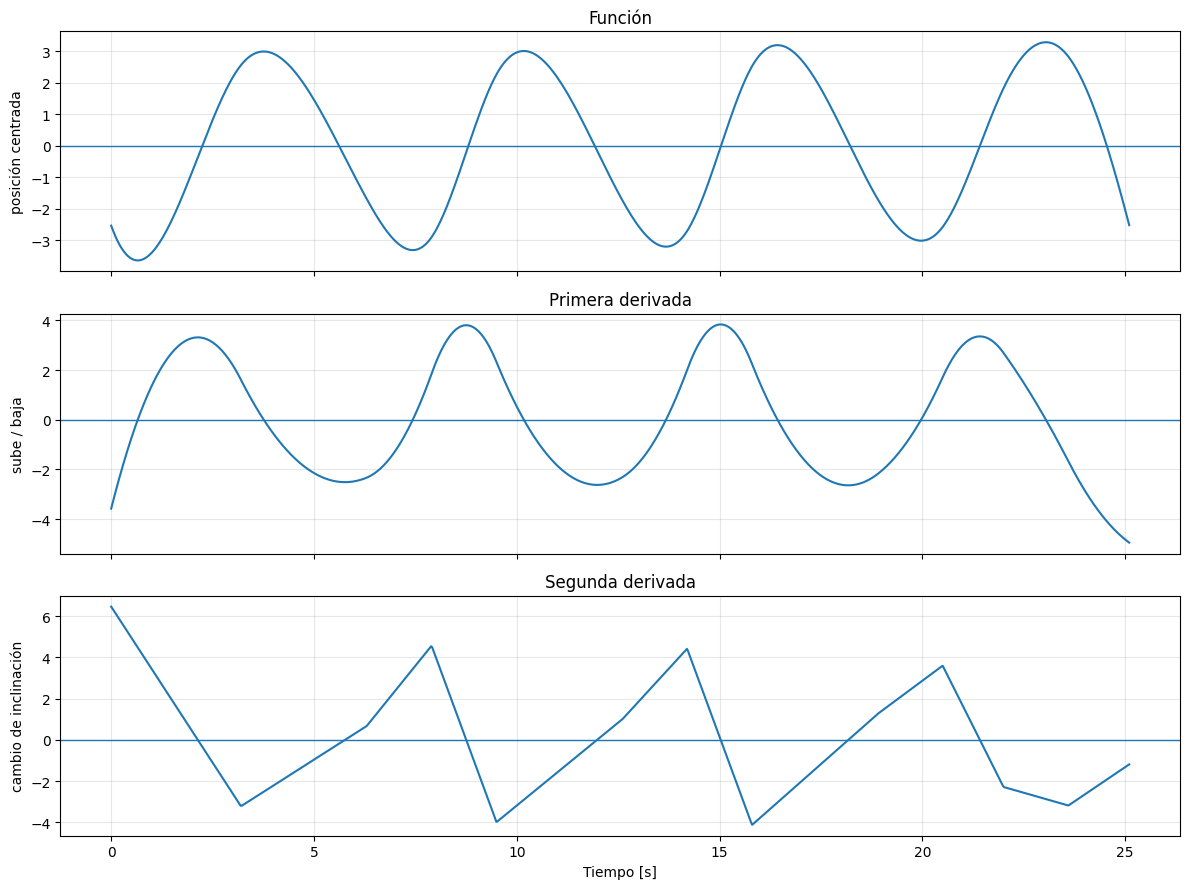

In [ ]:
primera_derivada = spline.derivative(1)
segunda_derivada = spline.derivative(2)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(tiempo_suave, spline(tiempo_suave))
axes[0].axhline(0, linewidth=1)
axes[0].set_ylabel("posición centrada")
axes[0].set_title("Función")

axes[1].plot(tiempo_suave, primera_derivada(tiempo_suave))
axes[1].axhline(0, linewidth=1)
axes[1].set_ylabel("sube / baja")
axes[1].set_title("Primera derivada")

axes[2].plot(tiempo_suave, segunda_derivada(tiempo_suave))
axes[2].axhline(0, linewidth=1)
axes[2].set_ylabel("cambio de inclinación")
axes[2].set_title("Segunda derivada")
axes[2].set_xlabel("Tiempo [s]")

for eje_grafico in axes:
    eje_grafico.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Encontrar máximos y mínimos de forma aproximada

Un máximo aparece cuando la curva deja de subir y comienza a bajar.  
Un mínimo aparece cuando deja de bajar y comienza a subir.

La computadora busca esos cambios en una malla de puntos.

,tiempo,valor centrado,tipo
0,0.678378,-3.631649,mínimo
1,3.768765,2.991979,máximo
2,7.437030,-3.305387,mínimo
3,10.175666,3.007630,máximo
4,13.693180,-3.196061,mínimo
5,16.431816,3.193055,máximo
6,19.974455,-3.006968,mínimo
7,23.064843,3.284996,máximo


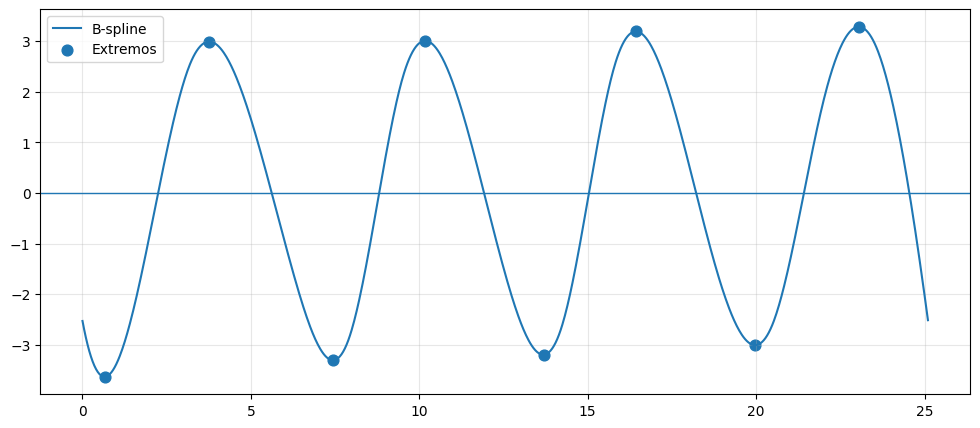

In [ ]:
pendiente = primera_derivada(tiempo_suave)
signo_pendiente = np.sign(pendiente)

cambios = np.where(np.diff(signo_pendiente) != 0)[0] + 1
tiempos_extremos = tiempo_suave[cambios]
valores_extremos = spline(tiempos_extremos)

tipos = []
for indice in cambios:
    antes = pendiente[indice - 1]
    despues = pendiente[indice]

    if antes > 0 and despues < 0:
        tipos.append("máximo")
    elif antes < 0 and despues > 0:
        tipos.append("mínimo")
    else:
        tipos.append("cambio pequeño")

extremos = pd.DataFrame({
    "tiempo": tiempos_extremos,
    "valor centrado": valores_extremos,
    "tipo": tipos,
})

display(extremos.head(20))

plt.figure(figsize=(12, 5))
plt.plot(tiempo_suave, spline(tiempo_suave), label="B-spline")
plt.scatter(tiempos_extremos, valores_extremos, s=60, label="Extremos")
plt.axhline(0, linewidth=1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 12. Resumen automático en lenguaje sencillo

In [ ]:
porcentaje_subiendo = 100 * np.mean(pendiente > 0)
porcentaje_bajando = 100 * np.mean(pendiente < 0)

print(f"Eje estudiado: {EJE}")
print(f"Tiempo subiendo: aproximadamente {porcentaje_subiendo:.1f}%")
print(f"Tiempo bajando: aproximadamente {porcentaje_bajando:.1f}%")
print(f"Máximos y mínimos aproximados: {len(extremos)}")

Eje estudiado: x
Tiempo subiendo: aproximadamente 46.4%
Tiempo bajando: aproximadamente 53.6%
Máximos y mínimos aproximados: 8


## 13. Actividades

1. Cambia `EJE = "x"` por `"y"` y después por `"z"`.
2. Prueba `SUAVIZADO = 0`, `0.02` y `0.2`.
3. Cambia `TRAYECTORIA` y compara los vuelos.
4. Explica con tus palabras qué significa que la curva cruce la línea cero.

### Lo importante de este nivel

No necesitas memorizar el código. Debes poder explicar:

- qué representa cada columna;
- por qué centramos los datos;
- qué hace una curva suave;
- cómo reconocer visualmente subida, bajada, máximos y mínimos.